# Decision Tree Model

CRISP-DM phase: Modelling + Evaluation

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, precision_score

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

In [3]:
#separating the features (X) from the level (y)
X_train = train.drop('level', axis=1)
y_train = train['level']
X_test = test.drop('level', axis=1)
y_test = test['level']

## 2. Cross-Validation

In [4]:
#stratified 5-fold cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 3. Base Model

In [5]:
#base model with all default settings
model_default = DecisionTreeClassifier(random_state=42)

In [6]:
#cross-validation predictions for the default model
y_pred_default = cross_val_predict(model_default, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_default, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.84      0.85      0.85      9546
             1 mild       0.63      0.62      0.62      4827
2 moderate or worse       0.58      0.57      0.57      1027

           accuracy                           0.76     15400
          macro avg       0.68      0.68      0.68     15400
       weighted avg       0.76      0.76      0.76     15400



#### Observation

With all default settings, the decision tree reaches a macro F1 of 0.68 and an accuracy of 76%. It finds 85% of okay students and 62% of mild students, but only 57% of moderate or worse students, so about 440 of the 1,027 students who need help most are missed. Precision and recall for level 2 are almost equal (58% and 57%), so the tree misses about as many level 2 students as it wrongly flags.

## 4. Class Weights

In [7]:
#model with balanced class weights
model_balanced = DecisionTreeClassifier(class_weight='balanced', random_state=42)
y_pred_balanced = cross_val_predict(model_balanced, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_balanced, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.85      0.84      0.84      9546
             1 mild       0.62      0.63      0.62      4827
2 moderate or worse       0.53      0.55      0.54      1027

           accuracy                           0.75     15400
          macro avg       0.67      0.67      0.67     15400
       weighted avg       0.76      0.75      0.75     15400



#### Observation

Unlike logistic regression, balanced class weights do not help the decision tree. Level 2 recall falls slightly from 57% to 55% (about 460 missed students instead of 440), level 2 precision falls from 58% to 53%, and macro F1 falls from 0.68 to 0.67. The other levels barely change.

This happens because the tree has no depth limit, so it keeps splitting until most leaves contain only one level. A leaf that holds only okay students still predicts okay however much extra weight level 2 students are given, so the weights have very little to change. The small drop in scores is about 20 students and is likely just a different tree being grown, not a real effect.

We keep the class weights for now, because once the depth of the tree is limited (Section 6), the leaves will contain a mix of levels and the weights should start to matter. The next section checks how large this unlimited tree has grown.

## 5. Tree Size

In [8]:
#fitting the balanced tree on the full training set
model_balanced.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_f

In [9]:
#how deep the tree grew and how many leaves it has
print(model_balanced.get_depth())
print(model_balanced.get_n_leaves())

37
3865


In [10]:
#accuracy on the training students it learned from
print(round(model_balanced.score(X_train, y_train), 3))

0.982


#### Observation

The balanced tree grew to a depth of 37 with 3,865 leaves. With 15,400 training students, that is an average of only about 4 students per leaf, so the tree has split the students into very small groups. A depth of 37 also means some students pass through 37 questions in a row, more than the 21 questions in the app, because the tree reuses the same question at different cut-off points (for example "phq_q1 ≤ 0.5" and later "phq_q1 ≤ 1.5").

On the training students it learned from, the tree's accuracy is 98.2%, but on unseen students in cross-validation it is only 75%. This gap of about 23 percentage points shows that the tree is overfitting: it has memorised the training students instead of learning patterns that apply to new students. The accuracy does not reach 100% because some students gave the same answers to all 21 questions but have different levels (their level depends on PHQ-9 questions 3 to 9, which are not features), and no tree can separate identical answers.

The next step limits the depth of the tree (max_depth) to reduce overfitting.

## 6. Choosing max_depth

### 6.1 Comparing Depths

In [11]:
#cross-validation with max_depth = 3 (very shallow tree)
model_d3 = DecisionTreeClassifier(class_weight='balanced', max_depth=3, random_state=42)
scores_d3 = cross_val_score(model_d3, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_d3.round(3))
print(scores_d3.mean().round(3), scores_d3.std().round(3))

[0.634 0.621 0.64  0.643 0.624]
0.632 0.009


In [12]:
#cross-validation with max_depth = 5
model_d5 = DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)
scores_d5 = cross_val_score(model_d5, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_d5.round(3))
print(scores_d5.mean().round(3), scores_d5.std().round(3))

[0.681 0.737 0.728 0.724 0.712]
0.716 0.019


In [13]:
#cross-validation with max_depth = 7
model_d7 = DecisionTreeClassifier(class_weight='balanced', max_depth=7, random_state=42)
scores_d7 = cross_val_score(model_d7, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_d7.round(3))
print(scores_d7.mean().round(3), scores_d7.std().round(3))

[0.705 0.733 0.702 0.717 0.7  ]
0.711 0.012


In [14]:
#cross-validation with max_depth = 10
model_d10 = DecisionTreeClassifier(class_weight='balanced', max_depth=10, random_state=42)
scores_d10 = cross_val_score(model_d10, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_d10.round(3))
print(scores_d10.mean().round(3), scores_d10.std().round(3))

[0.709 0.715 0.717 0.708 0.716]
0.713 0.004


In [15]:
#cross-validation with max_depth = 15 (deep tree)
model_d15 = DecisionTreeClassifier(class_weight='balanced', max_depth=15, random_state=42)
scores_d15 = cross_val_score(model_d15, X_train, y_train, cv=cv, scoring='f1_macro')
print(scores_d15.round(3))
print(scores_d15.mean().round(3), scores_d15.std().round(3))

[0.694 0.7   0.696 0.69  0.711]
0.699 0.007


In [16]:
#comparing the five depths
cv_results = pd.DataFrame({'max_depth': [3, 5, 7, 10, 15],
                           'mean f1_macro': [scores_d3.mean(), scores_d5.mean(), scores_d7.mean(), scores_d10.mean(), scores_d15.mean()],
                           'std': [scores_d3.std(), scores_d5.std(), scores_d7.std(), scores_d10.std(), scores_d15.std()]})
cv_results.round(4)

,max_depth,mean f1_macro,std
0,3,0.6323,0.0086
1,5,0.7164,0.0193
2,7,0.7115,0.0124
3,10,0.7130,0.0035
4,15,0.6985,0.0072


#### Observation

Limiting the depth of the tree clearly helps. The unlimited balanced tree had a macro F1 of 0.67, while depths 5, 7 and 10 all score about 0.71 to 0.72. Depth 5 has the highest mean (0.716), but depths 7 (0.712) and 10 (0.713) are within one standard deviation of it, so the three are effectively tied.

At depth 3 the score drops to 0.632, so a tree with only 3 questions in a row is too simple to separate the levels (underfitting). At depth 15 the score falls to 0.699, because the tree is starting to memorise the training students again (overfitting). The best depths are therefore in the middle.

We chose max_depth = 5 because it has the highest mean and is the simplest of the tied depths, so it overfits the least and is the easiest to draw and explain. Its fold scores vary more than the others (standard deviation 0.019), but the deeper trees do not give a real improvement. Even after tuning, the tree (0.716) is still below the logistic regression model (0.745).

### 6.2 Class Weights at the Chosen Depth

In [17]:
#chosen depth without class weights
model_noweights = DecisionTreeClassifier(max_depth=5, random_state=42)
y_pred_noweights = cross_val_predict(model_noweights, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_noweights, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.86      0.91      0.88      9546
             1 mild       0.71      0.67      0.69      4827
2 moderate or worse       0.73      0.50      0.59      1027

           accuracy                           0.81     15400
          macro avg       0.77      0.69      0.72     15400
       weighted avg       0.80      0.81      0.80     15400



In [18]:
#chosen depth with class weights
model_tuned = DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)
y_pred_tuned = cross_val_predict(model_tuned, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_tuned, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.94      0.78      0.85      9546
             1 mild       0.62      0.77      0.69      4827
2 moderate or worse       0.53      0.72      0.61      1027

           accuracy                           0.77     15400
          macro avg       0.69      0.76      0.72     15400
       weighted avg       0.81      0.77      0.78     15400



#### Observation

At a depth of 5, the class weights now make a clear difference. Without weights, the tree finds only 50% of moderate or worse students (about 515 missed), even though its level 2 precision is high (73%). With balanced weights, level 2 recall rises to 72% (about 290 missed), so the model finds about 225 more of the students who need help most. Recall for mild students also rises from 67% to 77%.

This confirms the explanation from Section 4. In the unlimited tree, almost every leaf held only one level, so the weights had nothing to change. With a depth of 5, each leaf holds hundreds of students from mixed levels, and the weights can now tip those leaves towards level 2. Since recall for level 2 is the main aim, we keep the class weights, and the final decision tree is max_depth = 5 with class_weight = 'balanced'.

### 6.3 Size of the Tuned Tree

In [19]:
#fitting the tuned tree on the full training set
model_tuned.fit(X_train, y_train)
print(model_tuned.get_depth())
print(model_tuned.get_n_leaves())

5
32


In [20]:
#training accuracy of the tuned tree, to compare with its cross-validation accuracy
print(round(model_tuned.score(X_train, y_train), 3))

0.774


#### Observation

The tuned tree has a depth of 5 and 32 leaves, the most a depth-5 tree can have, so every branch used all 5 questions. With 15,400 training students, that is about 480 students per leaf on average, compared with about 4 per leaf in the unlimited tree (3,865 leaves). Each rule the tree learned is now backed by hundreds of students, so it describes a real pattern rather than a few individual students.

The training accuracy is now 77.4%, almost the same as the cross-validation accuracy of 77%. In Section 5 the gap was about 23 percentage points (98.2% against 75%), so limiting the depth has removed the overfitting: the tree now does as well on new students as on the students it learned from. A tree this small is also easy to draw and explain, and simple to run inside the app.

## 7. Evaluation on the Test Set

### 7.1 Fitting the Final Decision Tree

After the previous tests, the best settings for the decision tree were found to be max_depth = 5 and balanced class weights. These settings are used for the final model on the test data.

In [21]:
#fitting on the full training set and predicting the test set
model = DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

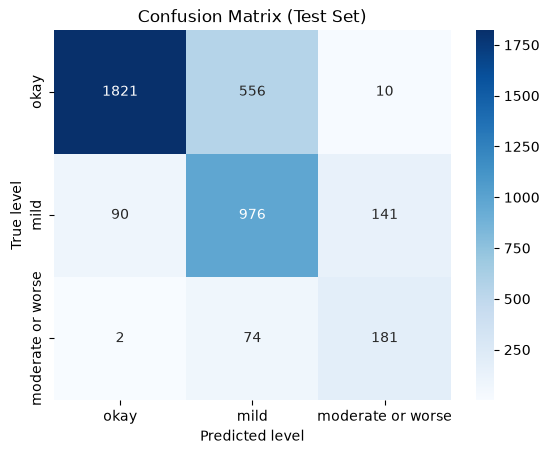

In [22]:
#confusion matrix of the test set
level_names = ['okay', 'mild', 'moderate or worse']
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names)
plt.xlabel('Predicted level')
plt.ylabel('True level')
plt.title('Confusion Matrix (Test Set)')
plt.show()

### 7.2 Classification Report

In [23]:
#per-class recall, precision and f1 on the test set
print(classification_report(y_test, y_pred, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.95      0.76      0.85      2387
             1 mild       0.61      0.81      0.69      1207
2 moderate or worse       0.55      0.70      0.61       257

           accuracy                           0.77      3851
          macro avg       0.70      0.76      0.72      3851
       weighted avg       0.82      0.77      0.78      3851



In [24]:
#macro f1 on the test set, to compare with the cross-validation score
print(round(f1_score(y_test, y_pred, average='macro'), 3))

0.718


#### Observation

On the test set the macro F1 is 0.718, almost identical to the cross-validation score of 0.716, so the tree is not overfitting and the cross-validation was a reliable guide. The recall is 76% for level 0, 81% for level 1 and 70% for level 2, so the tree finds about seven in ten moderate or worse students. The precision for level 2 is 55%, so about half of the students it flags as level 2 are really mild or okay. Predictions of level 0 are very reliable (precision 95%), but the tree predicts mild too often (precision 61%).

### 7.3 Confusion Matrix

Each row is the true level and each column is the predicted level, so the numbers on the diagonal are correct predictions.

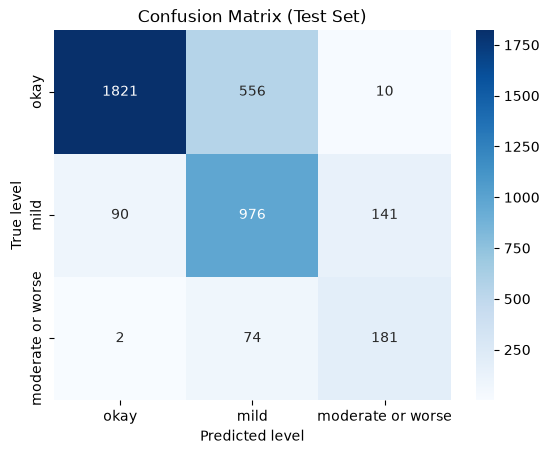

In [25]:
#confusion matrix of the test set
level_names = ['okay', 'mild', 'moderate or worse']
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names)
plt.xlabel('Predicted level')
plt.ylabel('True level')
plt.title('Confusion Matrix (Test Set)')
plt.show()

#### Observation

Of the 2,387 okay students, 1,821 are correct (76%), 556 are predicted mild and 10 are predicted level 2. Of the 1,207 mild students, 976 are correct (81%), 90 are predicted okay and 141 are predicted level 2. Of the 257 level 2 students, 181 are found (70%), 74 are predicted mild and 2 are predicted okay.

The biggest single mistake is okay students predicted as mild (556), much more than in logistic regression (399), which is why recall for okay students is lower. Most of the false alarms for level 2 are mild students (141 of 151), and 74 of the 76 missed level 2 students were still predicted mild, so as with logistic regression the boundary between mild and moderate or worse is the hardest one.

Most mistakes are between neighbouring levels, but 12 students are two levels away (10 okay students predicted as level 2 and 2 level 2 students predicted as okay), compared with 4 for logistic regression. A depth-5 tree makes predictions in a few large steps (32 leaves), so a student near a cut-off point can jump a whole level, while logistic regression changes its predictions more smoothly.

## 8. Comparison with the PHQ-2 Baseline

The PHQ-2 rule (the first two PHQ-9 questions added up, positive when 3 or more) is a yes/no rule, so it is compared with the model only on finding level 2 (moderate or worse) against everyone else. The cells below use the same test set.

In [26]:
#phq-2 rule on the test set: score of 3 or more = possible level 2
phq2_pred = (X_test['phq_q1'] + X_test['phq_q2']) >= 3

In [27]:
#level 2 recall and precision for the phq-2 rule and for the decision tree
comparison = pd.DataFrame({'method': ['PHQ-2 rule', 'Decision tree'],
                           'level 2 recall': [recall_score(y_test == 2, phq2_pred), recall_score(y_test == 2, y_pred == 2)],
                           'level 2 precision': [precision_score(y_test == 2, phq2_pred), precision_score(y_test == 2, y_pred == 2)]})
comparison.round(3)

,method,level 2 recall,level 2 precision
0,PHQ-2 rule,0.638,0.636
1,Decision tree,0.704,0.545


#### Observation

On the test set the PHQ-2 rule finds 63.8% of level 2 students (164 of 257) with a precision of 63.6%. The decision tree finds 70.4% (181 of 257), which is 17 more students, but its precision is lower at 54.5%. It raises 151 false alarms against 94 for the PHQ-2 rule (57 more), and most of them are mild students. So the tree beats the baseline on the main aim, recall for level 2, at the price of lower precision, and it can also separate level 0 from level 1, which the rule cannot do.

## 9. Looking Inside the Tree

### 9.1 Drawing the Tree

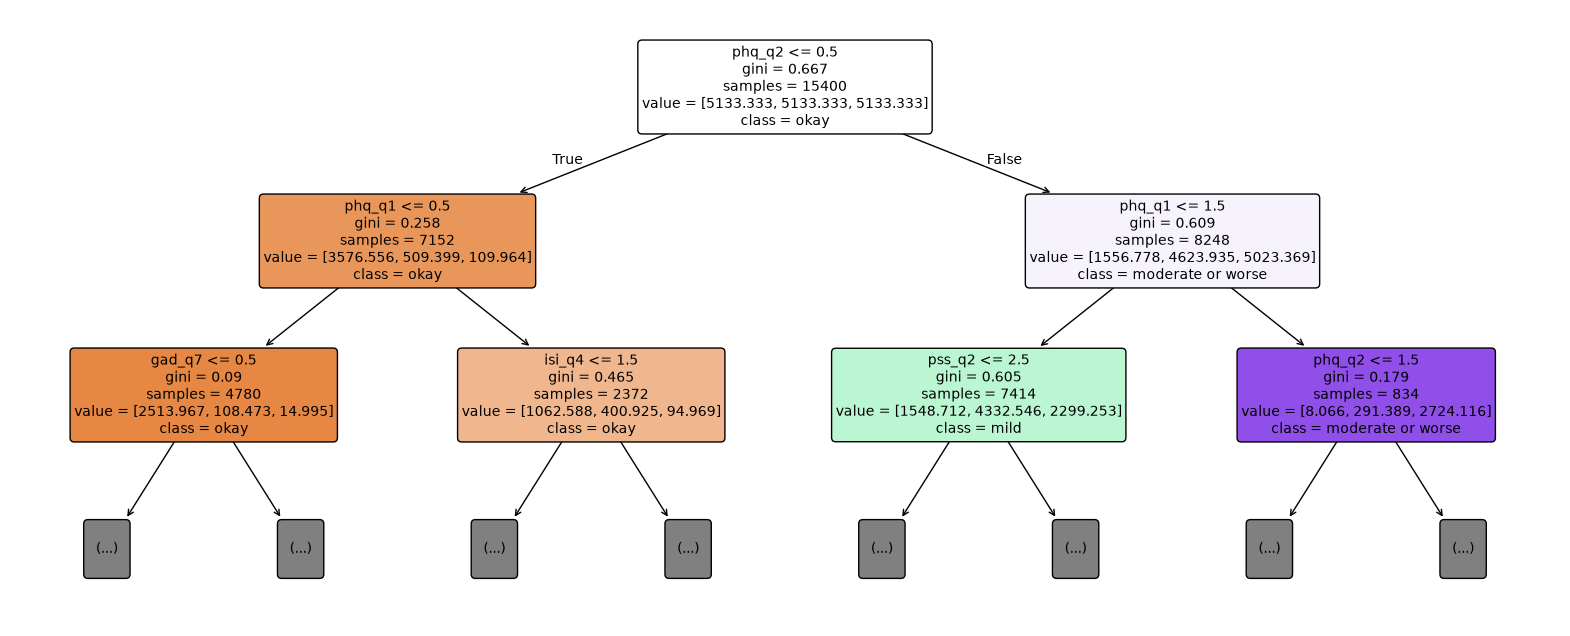

In [28]:
#top three levels of the tree, readable enough for a presentation
plt.figure(figsize=(20, 8))
plot_tree(model, max_depth=2, feature_names=X_train.columns, class_names=['okay', 'mild', 'moderate or worse'], filled=True, rounded=True, fontsize=10)
plt.show()

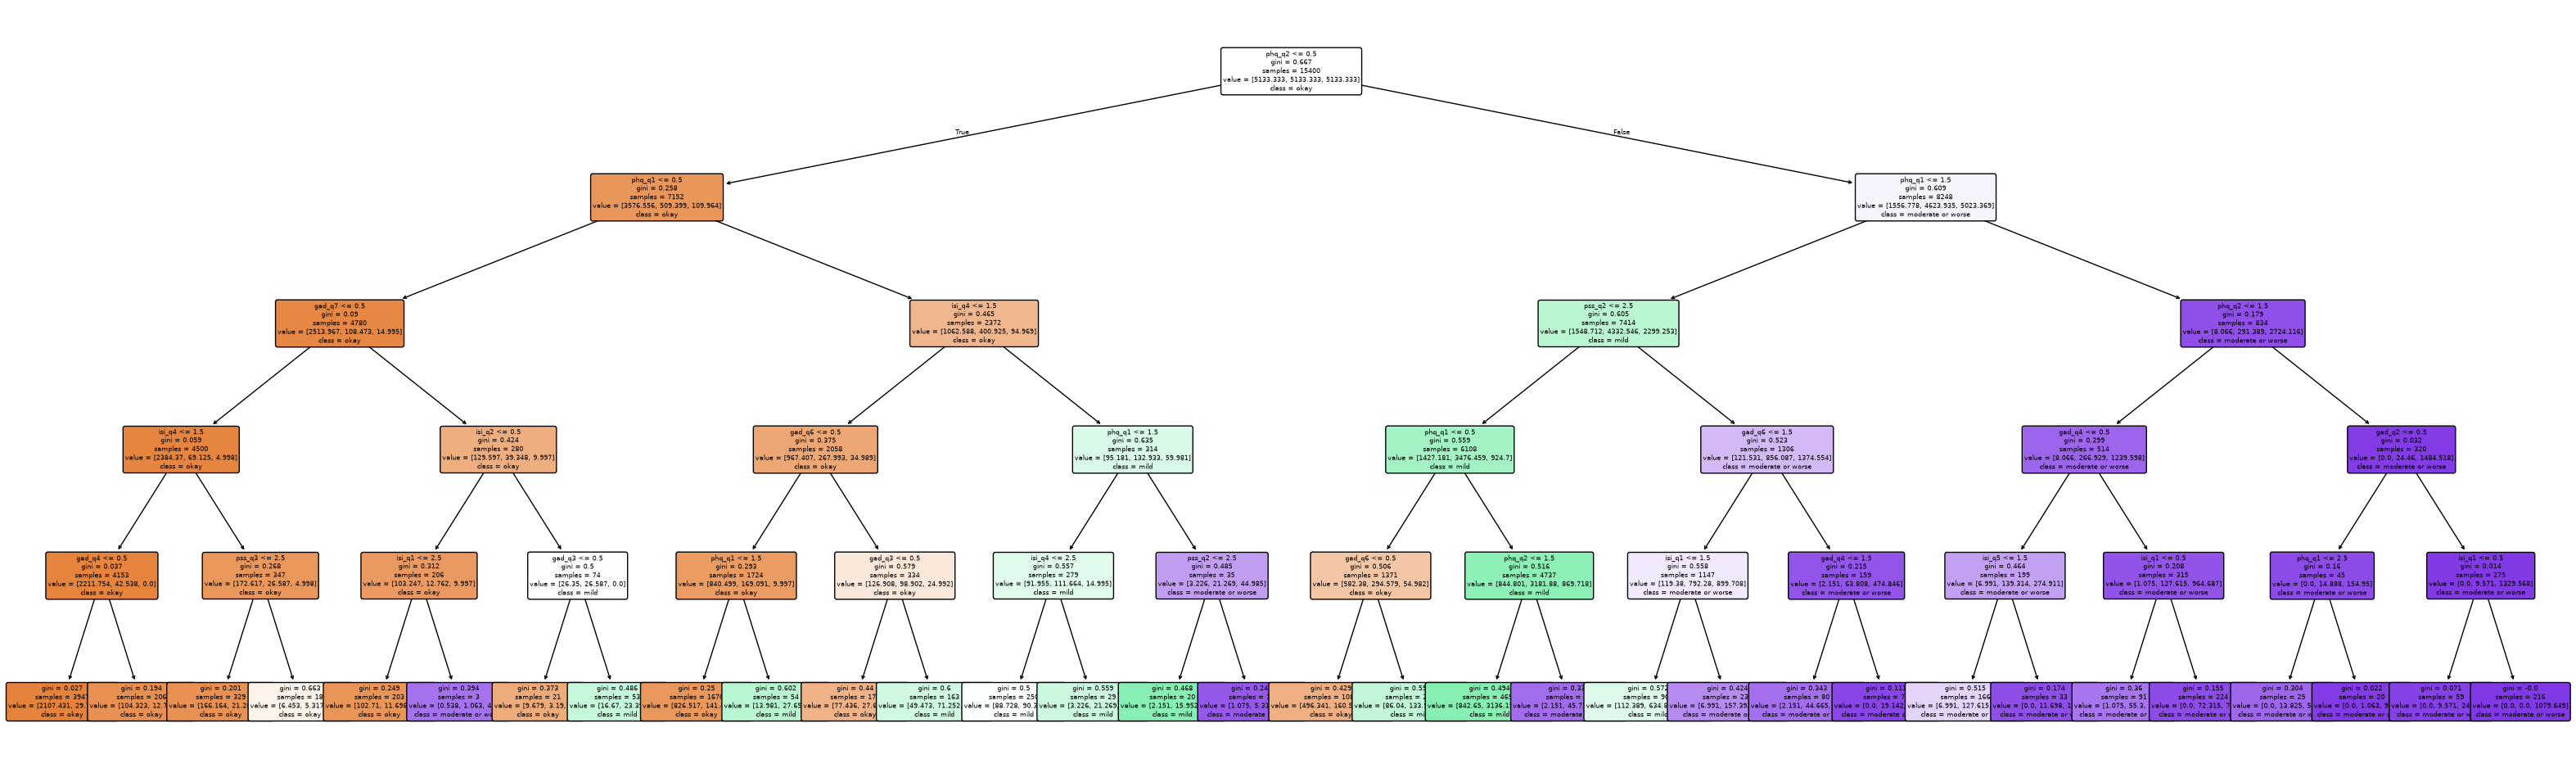

In [29]:
#the full depth-5 tree with all 32 leaves
plt.figure(figsize=(40, 12))
plot_tree(model, feature_names=X_train.columns, class_names=['okay', 'mild', 'moderate or worse'], filled=True, rounded=True, fontsize=6)
plt.show()

#### Observation

The first question the tree asks is phq_q2 ≤ 0.5, meaning whether the student answered 0 to the second PHQ question. At the top the Gini is 0.667, the highest possible for three levels, because the class weights make the three levels equal in weight (5,133 each). This one question splits the students into two very different groups.

Students who answered 0 (7,152 students, left side) are mostly okay. If they also answered 0 to phq_q1 (4,780 students), the box is almost pure (Gini 0.09): only about 3 of these 4,780 students are moderate or worse. Students who answered 1 or more (8,248 students, right side) are mostly mild or moderate or worse. If they also answered 2 or 3 to phq_q1 (834 students), the box is mostly moderate or worse (Gini 0.179), with about 545 level 2 students, 274 mild and only 15 okay.

The "value" numbers in each box are weighted by the class weights, not raw student counts. For example, the 2,724 for level 2 in that box equals about 545 students multiplied by their weight of about 5. Below the first two questions, the tree uses the other questionnaires (gad_q7, isi_q4 and pss_q2) to separate the students who are harder to place, especially in the mixed mild group (Gini 0.605). The full tree shows the same pattern: the left side ends mostly in okay leaves, the right side in moderate or worse leaves, and the mild leaves sit in between.

### 9.2 Feature Importance

In [30]:
#how much each question helped the tree, sorted from most to least important
importance = pd.DataFrame({'question': X_train.columns, 'importance': model.feature_importances_})
importance = importance.sort_values('importance', ascending=False)
importance.round(3)

,question,importance
0,phq_q2,0.486
1,phq_q1,0.340
7,pss_q2,0.090
2,gad_q6,0.034
16,isi_q4,0.016
12,isi_q1,0.014
5,gad_q4,0.007
18,isi_q5,0.004
11,gad_q7,0.003
4,gad_q3,0.003


#### Observation

The tree relies mainly on the two PHQ questions: phq_q2 has an importance of about 0.49 and phq_q1 about 0.34, so together they account for over 80% of the tree's decisions. This is expected, because the level comes from the full PHQ-9, and these are the only two PHQ-9 questions in the features. The next most useful questions are pss_q2 (about 0.09) and gad_q6 (about 0.03), followed by small contributions from isi_q4, isi_q1 and a few other GAD and ISI questions. These extra questions are what allow the tree to do more than the PHQ-2 rule, which uses only phq_q1 and phq_q2.

About half of the 21 questions have an importance of zero or almost zero, meaning the tree never or hardly ever used them. This does not mean these questions are useless: a depth-5 tree has only 31 question boxes, so it uses just the questions that were most useful at each step. A different tree could use different questions, so these importances should not be used on their own to remove questions from the app.

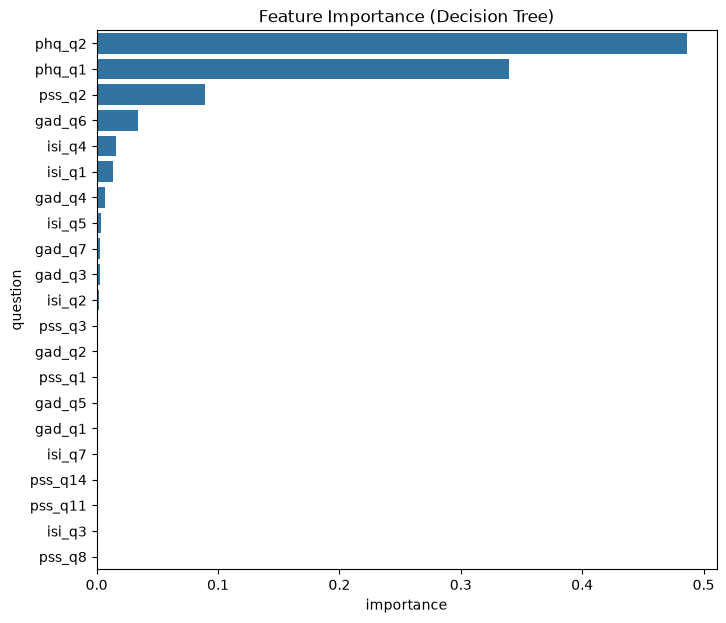

In [31]:
#bar chart of the importance of each question
plt.figure(figsize=(8, 7))
sns.barplot(data=importance, x='importance', y='question')
plt.title('Feature Importance (Decision Tree)')
plt.show()

## 10. Summary of the Decision Tree

- **Final model:** a decision tree with `max_depth = 5` and `class_weight='balanced'`, trained on the 21 selected questions to predict level 0 (okay), 1 (mild) or 2 (moderate or worse). The PHQ-9 total and questions 3 to 9 are not features.
- **Overfitting:** with default settings the tree grew to a depth of 37 with 3,865 leaves and reached 98.2% accuracy on the training students but only 75% in cross-validation. Limiting the depth to 5 (32 leaves) removed this gap (77.4% against 77%).
- **Class weights:** they had no effect on the unlimited tree, because almost every leaf held a single level, but at depth 5 they raised level 2 recall in cross-validation from 50% to 72%.
- **Validity:** stratified 5-fold cross-validation gave a macro F1 of 0.716, and the held-out test set gave 0.718, so the two agree.
- **Per-class results on the test set:** recall of 76% (okay), 81% (mild) and 70% (moderate or worse), with a precision of 55% for level 2. Most mistakes are between neighbouring levels, but 12 students were placed two levels away.
- **Against the PHQ-2 rule:** the tree finds more level 2 students (70% against 64%) but raises more false alarms (precision 55% against 64%).
- **Inside the tree:** the tree is small enough to draw and read. Its first two questions are phq_q2 and phq_q1, which make up over 80% of its importance, with pss_q2 and gad_q6 adding the most after them.
- **Limits:** the test set has only 257 level 2 students, mild against moderate or worse is the hardest split, some students have identical answers but different levels, a single tree can change noticeably with small changes in the data, and the questions were selected using all students before the split.